# 🛠️ Phase 5: Preprocessing Pipeline

This notebook sets up the data preprocessing pipeline for **SchemeMatch** applicant profiles (`data/applicants.csv`).
It standardizes numerical features and one-hot encodes categorical features to prepare the feature matrix for clustering in Phase 6.

---
## 1. Setup & Imports

In [1]:
import os
import pandas as pd
import numpy as np
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("Libraries successfully imported.")

Libraries successfully imported.


---
## 2. Load Data

Load `../data/applicants.csv`, inspect the dataset, and define feature lists (excluding `applicant_id`).

In [2]:
# Path to applicants dataset
data_path = os.path.join("..", "data", "applicants.csv")
df = pd.read_csv(data_path)

print(f"Loaded applicant data: {df.shape[0]} rows × {df.shape[1]} columns")

# Define numerical and categorical features (excluding 'applicant_id')
numerical_features = ['age', 'annual_income', 'funding_requirement']
categorical_features = ['sector', 'business_stage', 'location', 'social_category', 'purpose']

# Feature matrix excluding identifier
X = df[numerical_features + categorical_features]

print(f"Numerical features ({len(numerical_features)}): {numerical_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")
print(f"Features subset shape: {X.shape}")

Loaded applicant data: 400 rows × 9 columns
Numerical features (3): ['age', 'annual_income', 'funding_requirement']
Categorical features (5): ['sector', 'business_stage', 'location', 'social_category', 'purpose']
Features subset shape: (400, 8)


---
## 3. Build Preprocessing Pipeline

Construct a `ColumnTransformer` combining:
- `StandardScaler()` for numerical features (`age`, `annual_income`, `funding_requirement`)
- `OneHotEncoder(handle_unknown='ignore', sparse_output=False)` for categorical features

In [3]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

print("ColumnTransformer pipeline created:")
print(preprocessor)

ColumnTransformer pipeline created:
ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['age', 'annual_income',
                                  'funding_requirement']),
                                ('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['sector', 'business_stage', 'location',
                                  'social_category', 'purpose'])])


---
## 4. Fit, Transform & Verify

Fit and transform the feature matrix `X` into `X_processed`, then verify:
1. Original shape vs. transformed shape
2. Transformed feature names
3. Check for any NaN values
4. Mean and standard deviation of scaled numerical columns

In [4]:
# Fit the pipeline and transform the applicant features
X_processed = preprocessor.fit_transform(X)

# 1. Original vs Transformed shape
print("=" * 60)
print(f"Original feature shape:     {X.shape}")
print(f"Transformed shape (X_processed.shape): {X_processed.shape}")
print("=" * 60)

# 2. Transformed feature names
feature_names = preprocessor.get_feature_names_out()
print(f"\nFull list of transformed feature names ({len(feature_names)} features):")
for idx, name in enumerate(feature_names, start=1):
    print(f"  {idx:2d}. {name}")

# 3. Check for NaN values
nan_count = np.isnan(X_processed).sum()
print("\n" + "=" * 60)
print(f"Zero NaN Confirmation: {nan_count == 0} (Total NaN count: {nan_count})")

# 4. Mean and Standard Deviation of the first 3 scaled numerical columns
means = np.round(X_processed[:, :3].mean(axis=0), 2)
stds = np.round(X_processed[:, :3].std(axis=0), 2)

print("\nScaling Verification (first 3 numerical columns):")
for feat, m, s in zip(numerical_features, means, stds):
    print(f"  - {feat:<20s} Mean: {m:>5.2f} (expected ~0.00), Std: {s:>5.2f} (expected ~1.00)")
print("=" * 60)

Original feature shape:     (400, 8)
Transformed shape (X_processed.shape): (400, 24)

Full list of transformed feature names (24 features):
   1. num__age
   2. num__annual_income
   3. num__funding_requirement
   4. cat__sector_Agri-Allied
   5. cat__sector_Food Processing
   6. cat__sector_Manufacturing
   7. cat__sector_Service
   8. cat__sector_Trading
   9. cat__business_stage_Existing
  10. cat__business_stage_New
  11. cat__business_stage_Planning
  12. cat__location_Rural
  13. cat__location_Urban
  14. cat__social_category_General
  15. cat__social_category_Minority
  16. cat__social_category_OBC
  17. cat__social_category_SC
  18. cat__social_category_ST
  19. cat__social_category_Women
  20. cat__purpose_Business Expansion
  21. cat__purpose_Machinery & Equipment
  22. cat__purpose_Raw Materials
  23. cat__purpose_Unit Setup
  24. cat__purpose_Working Capital

Zero NaN Confirmation: True (Total NaN count: 0)

Scaling Verification (first 3 numerical columns):
  - age        

---
## 5. Save Preprocessor

Serialize the fitted `ColumnTransformer` object to `../models/preprocessor.joblib` for future inference and matching.

In [5]:
# Ensure models directory exists
models_dir = os.path.join("..", "models")
os.makedirs(models_dir, exist_ok=True)

# Destination file path
model_path = os.path.join(models_dir, "preprocessor.joblib")

# Save the fitted preprocessor using joblib
joblib.dump(preprocessor, model_path)

# Confirm file creation
file_size_kb = os.path.getsize(model_path) / 1024
print(f"Successfully saved preprocessor to: {model_path}")
print(f"File size: {file_size_kb:.2f} KB")

Successfully saved preprocessor to: ..\models\preprocessor.joblib
File size: 3.61 KB


---
## 6. Phase 6 (Part 1): Optimal K Evaluation

To determine the most appropriate number of clusters ($K$) for applicant segmentation, we evaluate $K \in [2, 10]$ using:
1. **Elbow Method (Inertia / WCSS)**: Within-cluster sum of squares, looking for an 'elbow' point where inertia reduction begins to plateau.
2. **Silhouette Score**: Evaluates cluster cohesion and separation ($[-1, 1]$), where higher values indicate well-separated, cohesive clusters.

In [6]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Evaluate k from 2 to 10 (inclusive)
k_values = list(range(2, 11))
inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_processed)
    inertias.append(kmeans.inertia_)
    score = silhouette_score(X_processed, kmeans.labels_)
    silhouette_scores.append(score)

# Print clean summary table
print(f"{'K':<4} | {'Inertia (WCSS)':<16} | {'Silhouette Score':<16}")
print("-" * 42)
for k, inertia, score in zip(k_values, inertias, silhouette_scores):
    print(f"{k:<4} | {inertia:<16.4f} | {score:<16.4f}")

K    | Inertia (WCSS)   | Silhouette Score
------------------------------------------
2    | 1945.1953        | 0.3051          
3    | 1664.2649        | 0.1691          
4    | 1573.3975        | 0.1508          
5    | 1500.6726        | 0.1132          
6    | 1436.7406        | 0.1074          
7    | 1388.0837        | 0.1119          
8    | 1335.9091        | 0.1061          
9    | 1306.1233        | 0.1056          
10   | 1278.7250        | 0.0989          


### 6.1 Visualize Elbow & Silhouette Plots

1x2 side-by-side plot comparing Inertia (Elbow Method) and Silhouette Score across $K \in [2, 10]$.

Saved visualization to: ..\visualizations\kmeans_elbow_silhouette.png
<string>:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


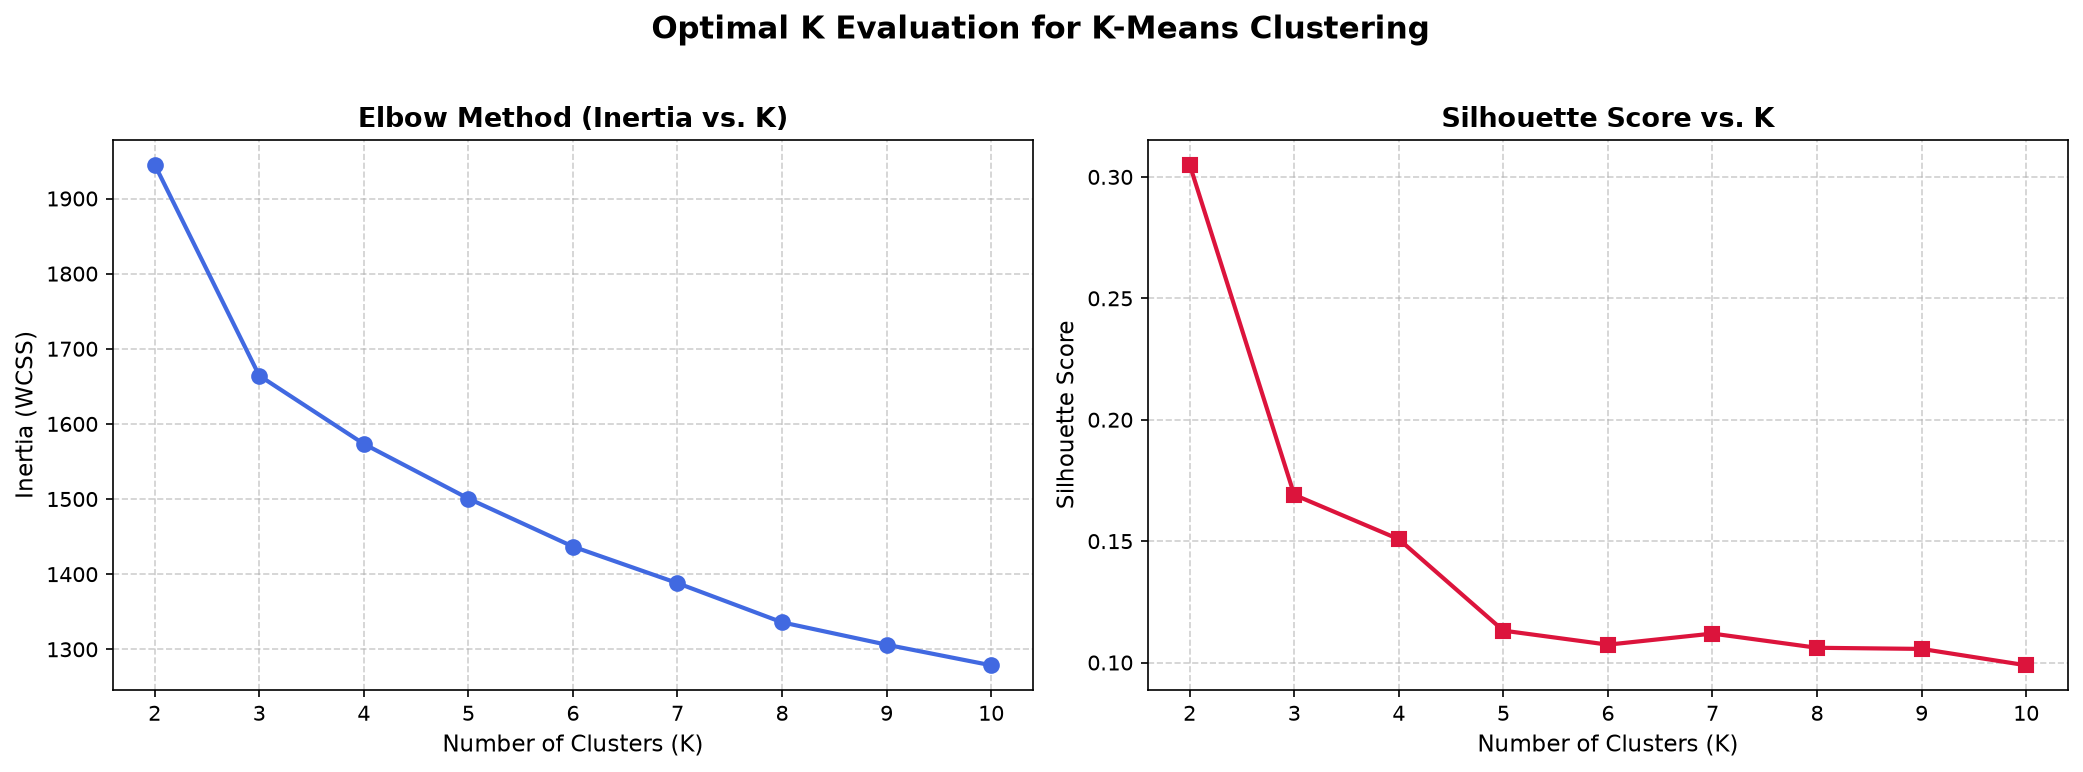

In [7]:
# Create 1x2 side-by-side figure
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left subplot: Elbow Method (K vs. Inertia)
axes[0].plot(k_values, inertias, marker='o', linewidth=2, color='royalblue', markersize=7)
axes[0].set_title("Elbow Method (Inertia vs. K)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Number of Clusters (K)", fontsize=11)
axes[0].set_ylabel("Inertia (WCSS)", fontsize=11)
axes[0].set_xticks(k_values)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Right subplot: Silhouette Score (K vs. Silhouette Score)
axes[1].plot(k_values, silhouette_scores, marker='s', linewidth=2, color='crimson', markersize=7)
axes[1].set_title("Silhouette Score vs. K", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Number of Clusters (K)", fontsize=11)
axes[1].set_ylabel("Silhouette Score", fontsize=11)
axes[1].set_xticks(k_values)
axes[1].grid(True, linestyle='--', alpha=0.6)

fig.suptitle("Optimal K Evaluation for K-Means Clustering", fontsize=15, fontweight='bold', y=1.02)
fig.tight_layout()

# Save figure to ../visualizations/kmeans_elbow_silhouette.png at 150 DPI
viz_path = os.path.join("..", "visualizations", "kmeans_elbow_silhouette.png")
fig.savefig(viz_path, dpi=150, bbox_inches='tight')
print(f"Saved visualization to: {viz_path}")
plt.show()

---
## 7. Phase 6 (Part 2): Final K-Means Model, PCA Visualization & Cluster Interpretation

Based on the evaluation of Inertia and Silhouette scores (and business segmentation requirements), we train the final **K-Means model with $K=4$ clusters**.
In this section, we:
1. Fit and serialize the final `KMeans` model (`kmeans_model.joblib`).
2. Attach cluster assignments to applicant profiles.
3. Generate detailed profile summaries for each cluster.
4. Visualize cluster distributions in 2D using Principal Component Analysis (PCA).

In [8]:
# Train final KMeans model with K=4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans.fit(X_processed)

# Save the trained model to ../models/kmeans_model.joblib
kmeans_model_path = os.path.join("..", "models", "kmeans_model.joblib")
joblib.dump(kmeans, kmeans_model_path)
print(f"Final KMeans model (K=4) trained and saved to: {kmeans_model_path}")
print(f"Model file size: {os.path.getsize(kmeans_model_path) / 1024:.2f} KB")

# Attach predicted cluster labels to a copy of applicants DataFrame
df_clustered = df.copy()
df_clustered["cluster"] = kmeans.labels_
print(f"\nAttached cluster labels to df_clustered. Cluster distribution:\n{df_clustered['cluster'].value_counts().sort_index().to_string()}")

Final KMeans model (K=4) trained and saved to: ..\models\kmeans_model.joblib
Model file size: 3.02 KB

Attached cluster labels to df_clustered. Cluster distribution:
cluster
0    119
1    143
2     64
3     74


### 7.1 Cluster Profile Summary

Inspecting demographic and operational characteristics across clusters 0 through 3:
- Numerical means: `age`, `annual_income`, and `funding_requirement`
- Categorical modes: `sector`, `business_stage`, `location`, `social_category`, and `purpose`

In [9]:
print("=" * 75)
print(f"{'CLUSTER PROFILE SUMMARY (K=4)':^75}")
print("=" * 75)

for c in range(4):
    sub = df_clustered[df_clustered["cluster"] == c]
    count = len(sub)
    pct = count / len(df_clustered) * 100
    
    mean_age = sub["age"].mean()
    mean_income = sub["annual_income"].mean()
    mean_funding = sub["funding_requirement"].mean()
    
    top_sector = sub["sector"].mode()[0]
    top_stage = sub["business_stage"].mode()[0]
    top_loc = sub["location"].mode()[0]
    top_cat = sub["social_category"].mode()[0]
    top_purpose = sub["purpose"].mode()[0]
    
    print(f"\n📊 CLUSTER {c} | Count: {count} applicants ({pct:.1f}%)")
    print("-" * 55)
    print(f"  • Mean Age:                {mean_age:.1f} years")
    print(f"  • Mean Annual Income:      ₹{mean_income:,.0f}")
    print(f"  • Mean Funding Need:       ₹{mean_funding:,.0f}")
    print(f"  • Top Sector:              {top_sector}")
    print(f"  • Top Business Stage:      {top_stage}")
    print(f"  • Top Location:            {top_loc}")
    print(f"  • Top Social Category:     {top_cat}")
    print(f"  • Top Purpose:             {top_purpose}")

print("\n" + "=" * 75)

                       CLUSTER PROFILE SUMMARY (K=4)                       

📊 CLUSTER 0 | Count: 119 applicants (29.8%)
-------------------------------------------------------
  • Mean Age:                30.8 years
  • Mean Annual Income:      ₹326,723
  • Mean Funding Need:       ₹473,782
  • Top Sector:              Service
  • Top Business Stage:      Existing
  • Top Location:            Urban
  • Top Social Category:     General
  • Top Purpose:             Working Capital

📊 CLUSTER 1 | Count: 143 applicants (35.8%)
-------------------------------------------------------
  • Mean Age:                23.3 years
  • Mean Annual Income:      ₹134,615
  • Mean Funding Need:       ₹214,545
  • Top Sector:              Agri-Allied
  • Top Business Stage:      New
  • Top Location:            Rural
  • Top Social Category:     Women
  • Top Purpose:             Unit Setup

📊 CLUSTER 2 | Count: 64 applicants (16.0%)
-------------------------------------------------------
  • Mean Age: 

### 7.2 PCA 2D Visualization

Dimensionality reduction via Principal Component Analysis (PCA) to project the 24-dimensional feature space onto 2 principal components (PC1, PC2) with cluster centroids marked.

PCA Component 1 explained variance: 35.73%
PCA Component 2 explained variance: 8.73%
Total Explained Variance (PC1 + PC2): 44.46%
Saved PCA visualization to: ..\visualizations\kmeans_clusters_pca.png


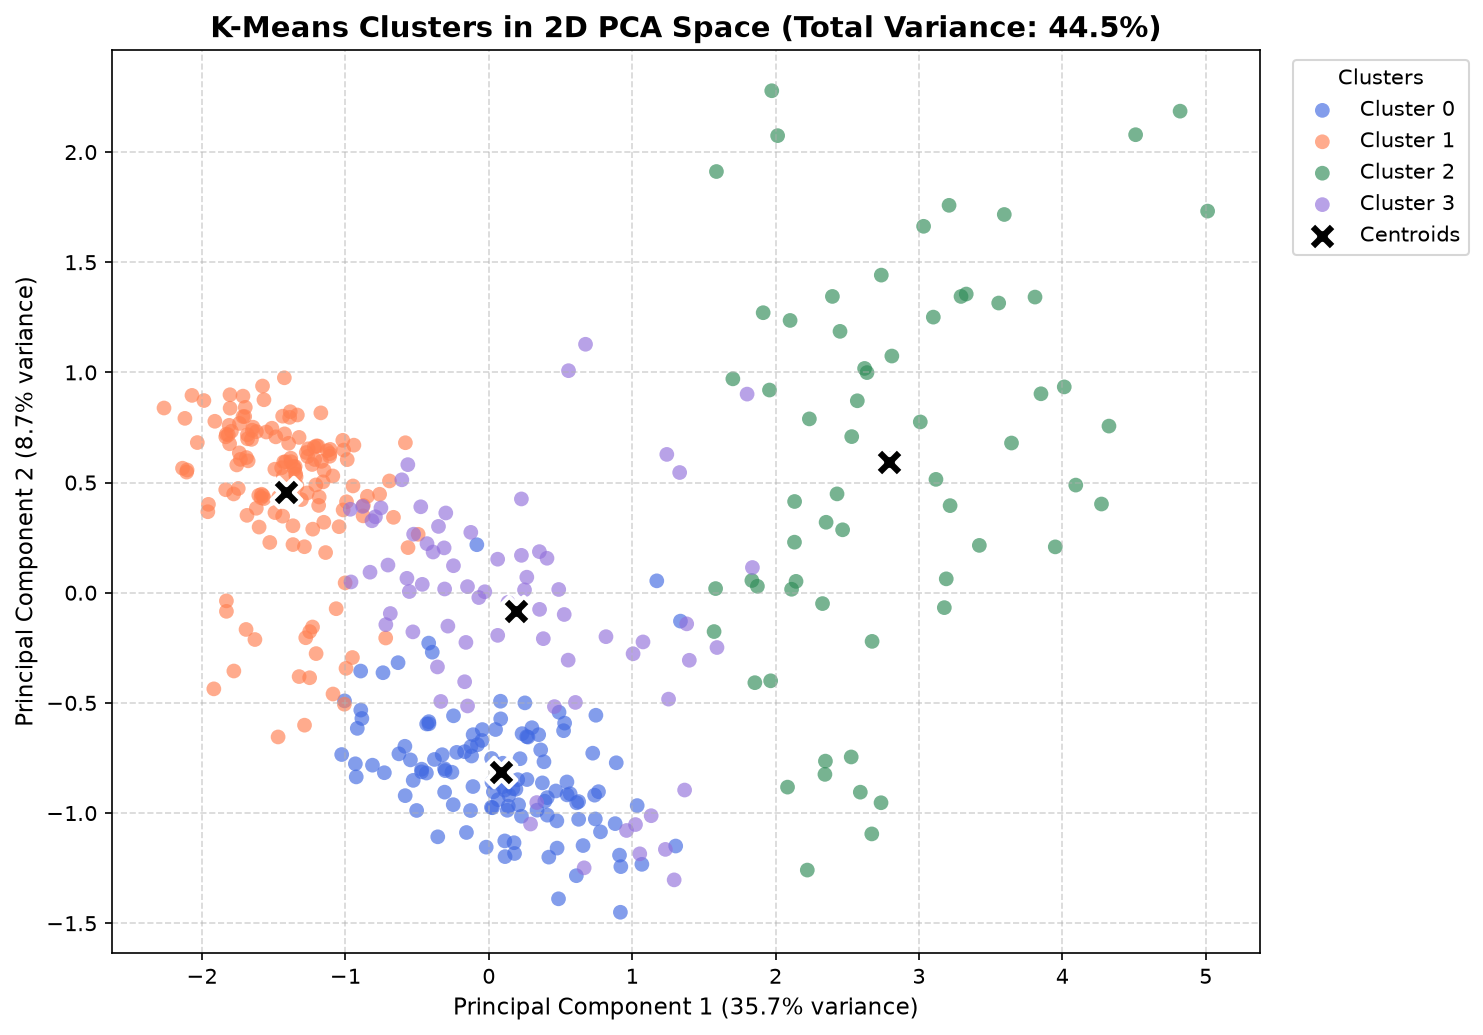

In [10]:
from sklearn.decomposition import PCA

# Fit PCA with 2 components on X_processed
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_processed)

# Transform cluster centers into 2D PCA space
centroids_pca = pca.transform(kmeans.cluster_centers_)

var_ratios = pca.explained_variance_ratio_
total_var = var_ratios.sum() * 100
print(f"PCA Component 1 explained variance: {var_ratios[0]*100:.2f}%")
print(f"PCA Component 2 explained variance: {var_ratios[1]*100:.2f}%")
print(f"Total Explained Variance (PC1 + PC2): {total_var:.2f}%")

# Create 2D scatter plot
fig, ax = plt.subplots(figsize=(10, 7))

cluster_colors = ['royalblue', 'coral', 'seagreen', 'mediumpurple']
cluster_names = [f"Cluster {i}" for i in range(4)]

for c in range(4):
    mask = (kmeans.labels_ == c)
    ax.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        c=cluster_colors[c],
        label=cluster_names[c],
        alpha=0.65,
        s=50,
        edgecolor='none'
    )

# Mark centroids
ax.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    c='black',
    marker='X',
    s=200,
    linewidths=2,
    edgecolor='white',
    label='Centroids',
    zorder=10
)

ax.set_title(f"K-Means Clusters in 2D PCA Space (Total Variance: {total_var:.1f}%)", fontsize=14, fontweight='bold')
ax.set_xlabel(f"Principal Component 1 ({var_ratios[0]*100:.1f}% variance)", fontsize=11)
ax.set_ylabel(f"Principal Component 2 ({var_ratios[1]*100:.1f}% variance)", fontsize=11)
ax.legend(title="Clusters", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=10)
ax.grid(True, linestyle='--', alpha=0.5)

fig.tight_layout()

# Save figure to ../visualizations/kmeans_clusters_pca.png at 150 DPI
pca_viz_path = os.path.join("..", "visualizations", "kmeans_clusters_pca.png")
fig.savefig(pca_viz_path, dpi=150, bbox_inches='tight')
print(f"Saved PCA visualization to: {pca_viz_path}")
plt.show()